# 01 Data exploration

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().parent
FIGURES = ANALYSIS_DIR / 'figures'
sys.path.insert(0, str(ANALYSIS_DIR))

from src.data_loader import (
    ASSIGNMENT_DIR,
    load_iperf,
    load_multi_node,
    load_single_node,
    parse_pidstat,
)

plt.rcParams.update(
    {
        'figure.figsize': (7, 4),
        'figure.dpi': 110,
        'savefig.dpi': 200,
        'savefig.bbox': 'tight',
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.grid': True,
        'grid.alpha': 0.3,
    }
)
SINGLE, MULTI = '#2a78d6', '#eb6834'
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
iperf = load_iperf()
single = load_single_node()
multi = load_multi_node()
{
    name: df.shape
    for name, df in [('iperf', iperf), ('single', single), ('multi', multi)]
}

{'iperf': (100, 10), 'single': (151, 23), 'multi': (360, 24)}

## Completeness

In [3]:
iperf.groupby('target_mbps').size().rename('runs').to_frame().T

target_mbps,100,200,300,400,500,600,700,800,900,1000
runs,10,10,10,10,10,10,10,10,10,10


In [4]:
single.groupby('rate').size().rename('runs').to_frame().T

rate,1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,12000,14000,16000,18000,19000,20000
runs,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,1


In [5]:
pd.crosstab(multi['rate'], [multi['attacker'], multi['source']])

attacker,node1,node3
source,json,json
rate,,
2000,10,10
4000,10,10
6000,10,10
8000,10,10
10000,10,10
12000,10,10
14000,10,10
16000,10,10


In [6]:
missing = {'node1', 'node3'} - set(multi['attacker'])
if missing:
    print(f'WARNING: no multi-node results or logs for {sorted(missing)}.')

In [7]:
pd.concat(
    {
        'single': single.groupby('session')['rate'].agg(
            ['min', 'max', 'nunique']
        ),
        'multi': multi.groupby('session')['rate'].agg(
            ['min', 'max', 'nunique']
        ),
    }
)

,,min,max,nunique
,session,,,
single,final_20261012_185544,1000,20000,16
multi,final_20261012_134628,2000,44000,18


## Did the client deliver the requested rate?

In [8]:
def delivered(df, per_attacker):
    offered = df['rate'] / (2 if per_attacker else 1)
    return (df['achieved_rate'] / offered).groupby(df['rate']).mean()


pd.DataFrame(
    {
        'single': delivered(single, False),
        'multi (per attacker)': delivered(multi, True),
    }
)

,single,multi (per attacker)
rate,,
1000,1.000,NaN
2000,1.000,1.000
3000,1.000,NaN
4000,1.000,1.000
5000,1.000,NaN
6000,1.000,1.000
7000,1.000,NaN
8000,1.000,1.000
9000,1.000,NaN


## Failures

In [9]:
failures = pd.concat(
    [single.assign(setup='single'), multi.assign(setup='multi')],
    ignore_index=True,
)
failures = failures[failures['failed'] > 0]
failures.groupby(['setup', 'rate'])[['failed', 'requests']].sum().assign(
    failed_pct=lambda d: 100 * d['failed'] / d['requests']
)

failed  requests  failed_pct
setup rate                               
multi 42000       1    630000       0.000
      44000       2    660007       0.000

In [10]:
kinds = failures.explode('error_kinds', ignore_index=True)
pd.crosstab([kinds['setup'], kinds['rate']], kinds['error_kinds'])

error_kinds  EOF
setup rate      
multi 42000    1
      44000    1

## Run-to-run variability

In [11]:
def cv(df, cols):
    g = df.groupby('rate')[cols]
    return g.std() / g.mean()


cv(single, ['throughput', 'lat_p50_ms', 'lat_p99_ms', 'server_cpu'])

,throughput,lat_p50_ms,lat_p99_ms,server_cpu
rate,,,,
1000,0.000,0.016,0.028,0.033
2000,0.000,0.011,0.012,0.017
3000,0.000,0.014,0.010,0.013
4000,0.000,0.040,0.012,0.053
5000,0.000,0.019,0.010,0.016
6000,0.000,0.004,0.013,0.010
7000,0.000,0.010,0.020,0.021
8000,0.000,0.017,0.017,0.012
9000,0.000,0.085,0.068,0.056


## Per-second CPU trace

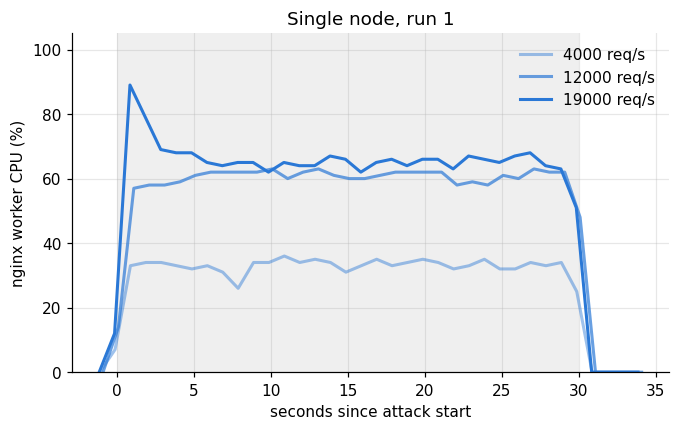

In [12]:
fig, ax = plt.subplots()
for rate, shade in [(4000, 0.45), (12000, 0.7), (19000, 1.0)]:
    row = single[(single['rate'] == rate) & (single['run'] == 1)].iloc[0]
    trace = parse_pidstat(
        ASSIGNMENT_DIR
        / 'vegeta-results'
        / row['session']
        / f'vegeta_attack_report_{rate}_run_1_cpu.txt'
    )
    seconds = (trace['time'] - row['start']).dt.total_seconds()
    ax.plot(
        seconds,
        trace['cpu'],
        color=SINGLE,
        alpha=shade,
        lw=2,
        label=f'{rate} req/s',
    )
ax.axvspan(0, 30, color='0.85', alpha=0.4, lw=0)
ax.set(
    xlabel='seconds since attack start',
    ylabel='nginx worker CPU (%)',
    ylim=(0, 105),
    title='Single node, run 1',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '01_cpu_trace.png')

## iperf3 raw view

In [13]:
iperf.groupby('target_mbps')[
    ['sent_mbps', 'goodput_mbps', 'lost_percent', 'jitter_ms']
].describe().T

target_mbps          100     200     300     400     500     600     700   \
sent_mbps    count 10.000  10.000  10.000  10.000  10.000  10.000  10.000   
             mean  99.992 199.983 299.975 399.969 499.963 599.959 699.955   
             std    0.001   0.000   0.000   0.000   0.001   0.001   0.001   
             min   99.991 199.983 299.975 399.969 499.962 599.958 699.954   
             25%   99.991 199.983 299.975 399.969 499.962 599.958 699.954   
             50%   99.991 199.983 299.975 399.969 499.962 599.958 699.955   
             75%   99.992 199.983 299.975 399.969 499.963 599.959 699.956   
             max   99.992 199.983 299.975 399.969 499.964 599.960 699.956   
goodput_mbps count 10.000  10.000  10.000  10.000  10.000  10.000  10.000   
             mean  99.992 199.983 299.975 399.969 499.963 599.959 699.955   
             std    0.001   0.000   0.000   0.000   0.001   0.001   0.001   
             min   99.991 199.983 299.975 399.969 499.962 599.958 699.953   
             25%   99.991 199.983 299.975 399.969 499.962 599.958 699.954   
             50%   99.991 199.983 299.975 399.969 499.962 599.958 699.955   
             75%   99.992 199.983 299.975 399.969 499.963 599.959 699.956   
             max   99.992 199.983 299.975 399.969 499.964 599.960 699.956   
lost_percent count 10.000  10.000  10.000  10.000  10.000  10.000  10.000   
             mean   0.000   0.000   0.000   0.000   0.000   0.000   0.000   
             std    0.000   0.000   0.000   0.000   0.000   0.000   0.000   
             min    0.000   0.000   0.000   0.000   0.000   0.000   0.000   
             25%    0.000   0.000   0.000   0.000   0.000   0.000   0.000   
             50%    0.000   0.000   0.000   0.000   0.000   0.000   0.000   
             75%    0.000   0.000   0.000   0.000   0.000   0.000   0.000   
             max    0.000   0.000   0.000   0.000   0.000   0.000   0.000   
jitter_ms    count 10.000  10.000  10.000  10.000  10.000  10.000  10.000   
             mean   0.006   0.013   0.010   0.008   0.006   0.005   0.005   
             std    0.003   0.001   0.001   0.000   0.000   0.000   0.001   
             min    0.004   0.011   0.009   0.007   0.006   0.004   0.004   
             25%    0.005   0.013   0.010   0.008   0.006   0.005   0.004   
             50%    0.005   0.013   0.010   0.008   0.006   0.005   0.004   
             75%    0.005   0.014   0.010   0.008   0.007   0.005   0.005   
             max    0.014   0.016   0.011   0.009   0.007   0.006   0.008   

target_mbps           800     900     1000  
sent_mbps    count  10.000  10.000  10.000  
             mean  799.953 899.952 999.933  
             std     0.001   0.001   0.036  
             min   799.952 899.951 999.899  
             25%   799.953 899.951 999.904  
             50%   799.953 899.952 999.926  
             75%   799.953 899.952 999.947  
             max   799.954 899.956 999.992  
goodput_mbps count  10.000  10.000  10.000  
             mean  799.934 899.931 934.004  
             std     0.036   0.027  47.915  
             min   799.843 899.864 868.644  
             25%   799.929 899.935 905.480  
             50%   799.953 899.940 912.689  
             75%   799.953 899.942 982.387  
             max   799.954 899.956 999.909  
lost_percent count  10.000  10.000  10.000  
             mean    0.002   0.002   6.593  
             std     0.004   0.003   4.791  
             min     0.000   0.000   0.004  
             25%     0.000   0.001   1.757  
             50%     0.000   0.001   8.722  
             75%     0.003   0.002   9.443  
             max     0.014   0.010  13.127  
jitter_ms    count  10.000  10.000  10.000  
             mean    0.004   0.003   0.004  
             std     0.001   0.001   0.002  
             min     0.004   0.001   0.002  
             25%     0.004   0.003   0.004  
             50%     0.004   0.004   0.004  
             75%     0.004   0.004   0.004  
             max  